# OTSM и ODDM: одна несущая в плоскости задержка–доплер

Раздел 2 `otfs_sim` показал: с прямоугольным импульсом OTFS — это **не** многочастотный сигнал. Отсчёт $l+nM$ кадра — комбинация $N$ символов одной строки задержки $l$:
$$s[l+nM]=\frac1{\sqrt N}\sum_kx[l,k]\,e^{\,j2\pi nk/N}.$$
Ось задержки ложится прямо во время — это **одна несущая**. Многочастотность есть только по оси доплера, и только внутри строки. Из этого вырастают два упрощения:

**OTSM** (orthogonal time sequency multiplexing; Thaj, Viterbo, Hong, 2021) заменяет DFT по оси доплера на **преобразование Уолша–Адамара**. Матрица $\pm1$: модулятор — только сложения, приёмник — тоже. Ось $k$ теперь не доплер, а **секвентность** (число смен знака функции Уолша). Сдвиг по доплеру больше не сдвиг по $k$, зато канал во времени тот же, и при линейном приёме ($H$ одинаков с точностью до унитарного поворота) вероятность ошибки почти та же.

**ODDM** (orthogonal delay-Doppler division multiplexing; Lin, Yuan, 2022) идёт с другой стороны: берёт отсчёты OTFS и формирует каждый **корень-Найквиста импульсом** шириной $T/M$ вместо прямоугольного окна длины $T$ на «символ OFDM». Получается обычная одночастотная передача с RRC-фильтром. Спектр компактный, а импульс $u(t)=\sum_n a(t-nT)$ ортогонален своим сдвигам на решётке $(mT/M,\;n/NT)$ — это **DD-ортогональный импульс**, существование которого долго обсуждалось.

Последний ноутбук серии: OTFS (`otfs_sim`) → Zak-OTFS (`zak_sim`) → AFDM (`afdm_sim`) / OCDM (`ocdm_sim`) → OTSM/ODDM.

1. Функции Уолша и одна несущая по задержке · 2. Канал в области задержка–секвентность · 3. BER: OTSM против OTFS · 4. ODDM: спектр и DD-ортогональность

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.special import erfc
from scipy.linalg import hadamard

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
M, N = 64, 16          # задержка × доплер/секвентность, как в otfs_sim
DF = 15e3
L_CP = 8
FC_GHZ = 4.0
SPEED_KMH = 500
P_PATHS = 5
BETA = 0.25            # скругление RRC-импульса ODDM
FRAMES = 30

rng = np.random.default_rng(SEED)

## Примитивы: Уолш–Адамар (быстрый), кадры OTFS/OTSM, канал, эффективная матрица

In [2]:
MN = M * N
FS = M * DF; T = 1 / DF
NU_MAX = SPEED_KMH / 3.6 * FC_GHZ * 1e9 / 3e8
QPSK = np.array([1 + 1j, -1 + 1j, 1 - 1j, -1 - 1j]) / np.sqrt(2)

def crandn(shape, rng):
    return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

def qpsk_bits(B, rng):
    b = rng.integers(0, 2, (B, MN, 2))
    return b, QPSK[b[..., 0] + 2 * b[..., 1]]

def hard_bits(z):
    return np.stack([z.real < 0, z.imag < 0], -1).astype(int)

# ---------- Уолш–Адамар в порядке секвентности (число смен знака) ----------
H_N = hadamard(N)
SEQ = np.argsort([np.sum(np.diff(r) != 0) for r in H_N])
WAL = H_N[SEQ] / np.sqrt(N)                      # строка k — функция Уолша с k сменами знака

def fwht(a):
    """быстрое WHT по последней оси: только сложения и вычитания, N·log₂N операций"""
    a = a.copy(); h = 1
    while h < a.shape[-1]:
        a = a.reshape(a.shape[:-1] + (-1, 2, h))
        a = np.concatenate([a[..., 0, :] + a[..., 1, :], a[..., 0, :] - a[..., 1, :]], -1)
        a = a.reshape(a.shape[:-2] + (-1,)); h *= 2
    return a

# ---------- три способа превратить DD-сетку в сигнал ----------
def frame(x, kind):
    """x[l,k] (…, M·N) → N блоков по M отсчётов + один CP. 'otfs': IDFT по оси k; 'otsm': WHT по оси k."""
    X = x.reshape(x.shape[:-1] + (M, N))
    B = np.fft.ifft(X, axis=-1) * np.sqrt(N) if kind == "otfs" else X @ WAL      # столбец n — блок n
    s = B.swapaxes(-1, -2).reshape(x.shape[:-1] + (MN,))
    return np.concatenate([s[..., -L_CP:], s], -1)

def unframe(r, kind):
    Y = r[..., L_CP:L_CP + MN].reshape(r.shape[:-1] + (N, M)).swapaxes(-1, -2)
    Z = np.fft.fft(Y, axis=-1) / np.sqrt(N) if kind == "otfs" else Y @ WAL.T
    return Z.reshape(r.shape[:-1] + (MN,))

def draw_paths(rng):
    p = np.exp(-np.arange(P_PATHS) / 1.5); p /= p.sum()
    nu = NU_MAX * np.cos(rng.uniform(0, 2 * np.pi, P_PATHS))
    return [(np.sqrt(pi) * crandn((), rng), l, v) for l, (pi, v) in enumerate(zip(p, nu))]

def channel(s, paths):
    n = np.arange(s.shape[-1]); r = np.zeros(s.shape, complex)
    for h, l, nu in paths:
        r[..., l:] += h * np.exp(2j * np.pi * nu * n[l:] / FS) * s[..., :s.shape[-1] - l]
    return r

def eff_matrix(paths, kind):
    return unframe(channel(frame(np.eye(MN, dtype=complex), kind), paths), kind).T

def lmmse(H, y, n0):
    return np.linalg.solve(H.conj().T @ H + n0 * np.eye(H.shape[1]), H.conj().T @ y.T).T

# самопроверки
assert np.allclose(WAL @ WAL.T, np.eye(N)), "WHT"
_a = crandn((3, N), rng)
assert np.allclose(fwht(_a)[:, SEQ] / np.sqrt(N), _a @ WAL.T), "fast WHT"
_b, _x = qpsk_bits(2, rng)
for kind in ("otfs", "otsm"):
    assert np.allclose(unframe(frame(_x, kind), kind), _x)
print(f"Сетка {M}×{N}, ν_max = {NU_MAX:.0f} Гц = {NU_MAX*N*T:.2f} бина 1/(NT); CP {L_CP} отсч. на кадр")

Сетка 64×16, ν_max = 1852 Гц = 1.98 бина 1/(NT); CP 8 отсч. на кадр


## 1. Функции Уолша и одна несущая по задержке
Слева — функции Уолша в порядке секвентности: строка $k$ меняет знак ровно $k$ раз. Это «дискретные синусоиды» из $\pm1$, и они ортогональны. Справа — один символ $(l,k)$ во времени у OTFS и у OTSM: в обоих случаях это $N$ импульсов в позициях $l+nM$. Разница только в коэффициентах: $e^{j2\pi nk/N}$ (вращающаяся фаза) против $\pm1$ (функция Уолша).

Модулятор OTFS на кадр — $M$ преобразований DFT длины $N$: $\tfrac{MN}{2}\log_2N$ комплексных умножений. Модулятор OTSM — $M$ быстрых WHT: **ни одного умножения**, $MN\log_2N$ сложений. В numpy это не видно: оба быстрые, FFT даже быстрее из-за оптимизированной библиотеки. Выигрыш появляется в железе, где умножитель занимает в разы больше площади и энергии, чем сумматор.

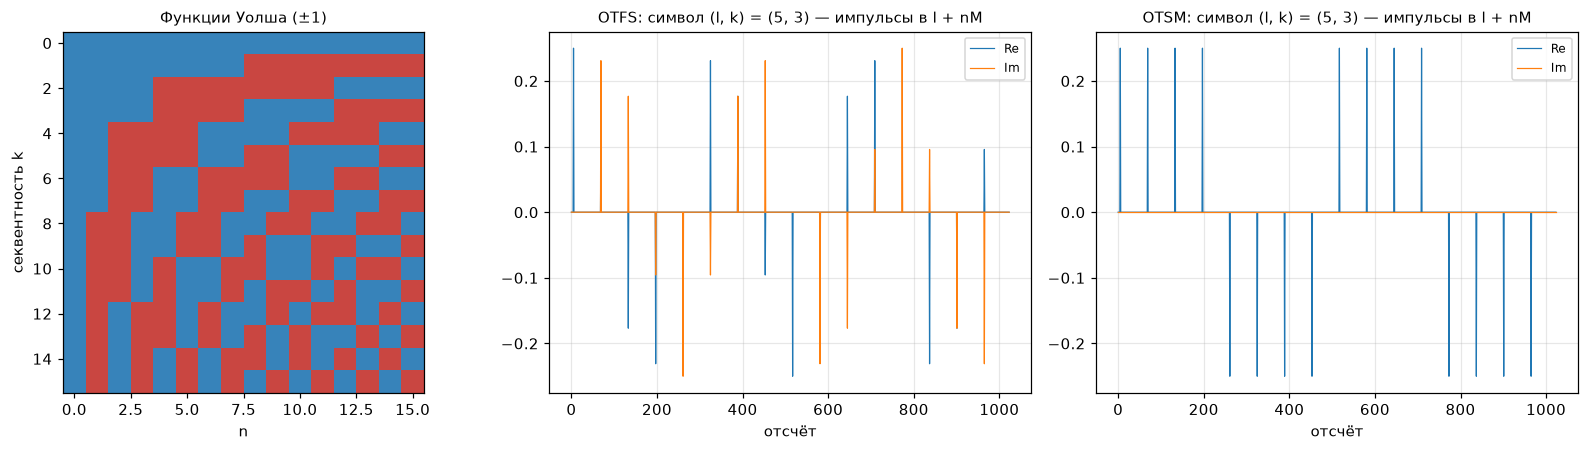

Число смен знака по строкам: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
Оба — «одна несущая по задержке»: символ (l, k) живёт только в отсчётах l + nM; различаются лишь коэффициенты импульсов: e^(j2πnk/N) у OTFS, ±1 у OTSM
Модулятор на кадр: IDFT_N — 2048 комплексных умножений + столько же сложений; WHT_N — 0 умножений и 4096 сложений
(на numpy время ничего не доказывает: FFT 0.007 мс/кадр против WHT 0.028 мс/кадр — выигрыш WHT в железе, где умножитель дороже сумматора)


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].imshow(WAL * np.sqrt(N), cmap="RdBu", vmin=-1.5, vmax=1.5); ax[0].grid(False)
ax[0].set_xlabel("n"); ax[0].set_ylabel("секвентность k"); ax[0].set_title("Функции Уолша (±1)", fontsize=10)
l0, k0 = 5, 3
for a, kind, t in ((ax[1], "otfs", "OTFS"), (ax[2], "otsm", "OTSM")):
    x = np.zeros(MN, complex); x[l0 * N + k0] = 1
    s = frame(x, kind)[L_CP:]
    a.plot(np.arange(MN), s.real, "C0", lw=0.8, label="Re"); a.plot(np.arange(MN), s.imag, "C1", lw=0.8, label="Im")
    a.set_xlabel("отсчёт"); a.legend(fontsize=8)
    a.set_title(f"{t}: символ (l, k) = ({l0}, {k0}) — импульсы в l + nM", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Число смен знака по строкам: {[int(np.sum(np.diff(r) != 0)) for r in WAL]}")
print(f"Оба — «одна несущая по задержке»: символ (l, k) живёт только в отсчётах l + nM; различаются лишь коэффициенты импульсов: e^(j2πnk/N) у OTFS, ±1 у OTSM")

# сложность модулятора
B = 200; _, xb = qpsk_bits(B, rng); Xb = xb.reshape(B, M, N)
t = time.perf_counter(); [np.fft.ifft(Xb, axis=-1) for _ in range(20)]; t_fft = (time.perf_counter() - t) / 20
t = time.perf_counter(); [fwht(Xb) for _ in range(20)]; t_wht = (time.perf_counter() - t) / 20
print(f"Модулятор на кадр: IDFT_N — {M*N//2*int(np.log2(N))} комплексных умножений + столько же сложений; WHT_N — 0 умножений и {M*N*int(np.log2(N))} сложений")
print(f"(на numpy время ничего не доказывает: FFT {t_fft*1e3/B:.3f} мс/кадр против WHT {t_wht*1e3/B:.3f} мс/кадр — выигрыш WHT в железе, где умножитель дороже сумматора)")

## 2. Канал в области задержка–секвентность
Отклик на пилот: у OTFS доплер — сдвиг по оси $k$, отклик компактен. У OTSM доплер «перемешивает» секвентности: функции Уолша не собственные для сдвига частоты, и отклик расползается по большему числу $k$, то есть матрица канала **менее разрежена**: 99 % энергии строки — в 34 элементах против 25 у OTFS. Поэтому OTSM-приёмники работают во **временной** области (итеративный Гаусс–Зейдель по разреженной временной матрице, Thaj et al.), а не по отклику в DS-области.

При этом сингулярные числа $H_\text{OTSM}$ и $H_\text{OTFS}$ совпадают до машинной точности. Обе матрицы — это один и тот же временной канал, повёрнутый разными унитарными преобразованиями. Ёмкость одинакова, а линейные детекторы различаются только тем, как ошибка распределяется по символам.

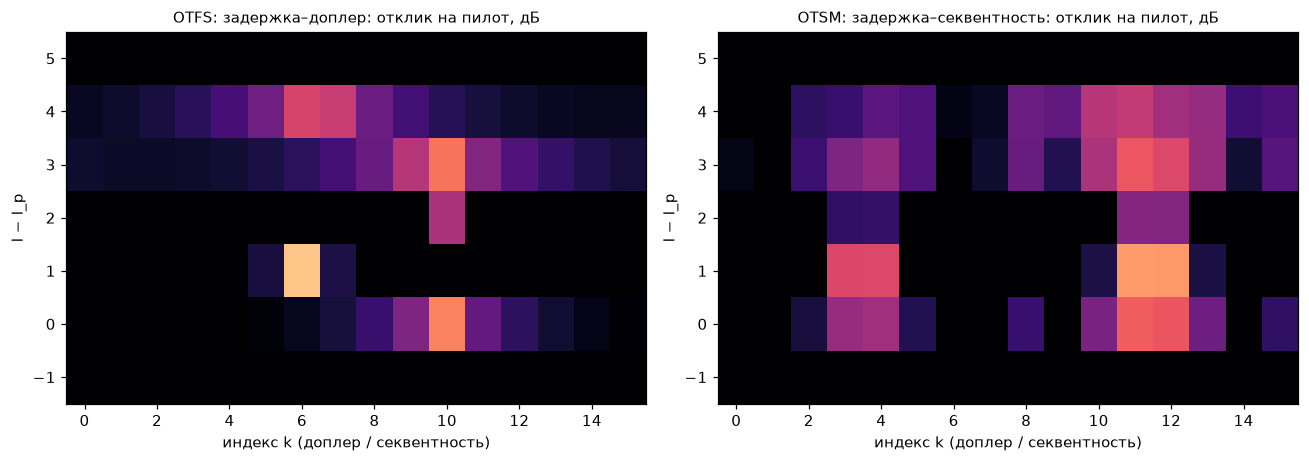

OTFS: элементов строки на 99 % энергии — 25.0 (из 1024)
OTSM: элементов строки на 99 % энергии — 34.2 (из 1024)


Сингулярные числа совпадают (обе — унитарные перестановки одного временного канала): max|σ_OTFS − σ_OTSM| = 8.9e-15


In [4]:
pth = draw_paths(np.random.default_rng(4))
Ho, Hs = eff_matrix(pth, "otfs"), eff_matrix(pth, "otsm")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
lp, kp = M // 2, N // 2
for a, Hm, t in ((ax[0], Ho, "OTFS: задержка–доплер"), (ax[1], Hs, "OTSM: задержка–секвентность")):
    col = np.abs(Hm[:, lp * N + kp]).reshape(M, N)
    a.imshow(20 * np.log10(col[lp - 1:lp + P_PATHS + 1] + 1e-6), origin="lower", aspect="auto", cmap="magma", vmin=-40, vmax=0,
             extent=[-0.5, N - 0.5, -1.5, P_PATHS + 0.5])
    a.set_xlabel("индекс k (доплер / секвентность)"); a.set_ylabel("l − l_p"); a.set_title(f"{t}: отклик на пилот, дБ", fontsize=10); a.grid(False)
plt.tight_layout(); plt.show()
for nm, Hm in (("OTFS", Ho), ("OTSM", Hs)):
    e = np.sort(np.abs(Hm)**2, 1)[:, ::-1]; e = np.cumsum(e, 1) / e.sum(1, keepdims=True)
    print(f"{nm}: элементов строки на 99 % энергии — {np.mean(np.argmax(e > 0.99, 1) + 1):.1f} (из {MN})")
print(f"Сингулярные числа совпадают (обе — унитарные перестановки одного временного канала): max|σ_OTFS − σ_OTSM| = {np.max(np.abs(np.linalg.svd(Ho, compute_uv=False) - np.linalg.svd(Hs, compute_uv=False))):.1e}")

## 3. BER: OTSM против OTFS
Тот же канал (500 км/ч, 5 лучей, дробный доплер), LMMSE у обеих. Кривые практически совпадают: каждый символ OTSM, как и OTFS, размазан по всем $N$ блокам кадра, то есть по времени. Разнесение по доплеру достаётся ему так же. Результат Thaj et al. воспроизводится: OTSM даёт ту же BER, что OTFS, при модуляторе без умножений.

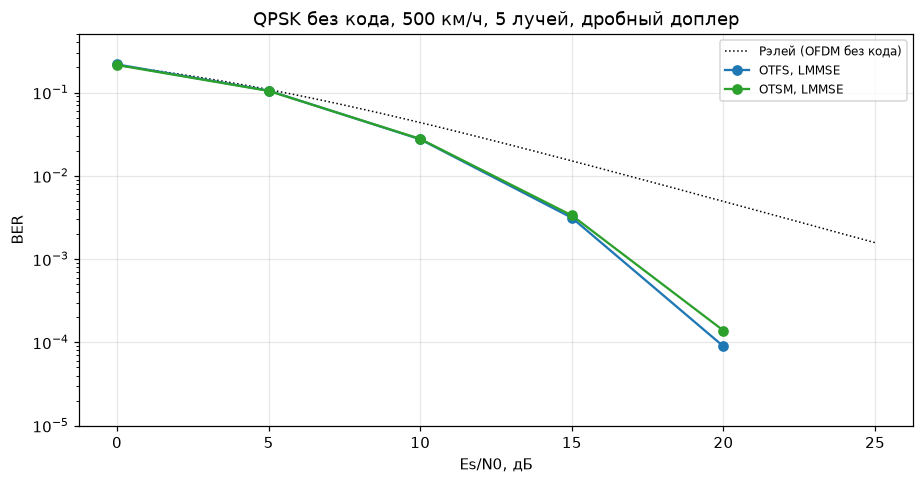

SNR  0 дБ: OTFS 2.2e-01, OTSM 2.1e-01
SNR  5 дБ: OTFS 1.1e-01, OTSM 1.0e-01
SNR 10 дБ: OTFS 2.7e-02, OTSM 2.8e-02
SNR 15 дБ: OTFS 3.1e-03, OTSM 3.3e-03
SNR 20 дБ: OTFS 9.0e-05, OTSM 1.4e-04
SNR 25 дБ: OTFS 0.0e+00, OTSM 0.0e+00


In [5]:
snrs = np.arange(0, 26, 5)
ber = {k: np.zeros(len(snrs)) for k in ("otfs", "otsm")}
for f in range(FRAMES):
    pth = draw_paths(rng)
    for kind in ber:
        H = eff_matrix(pth, kind); b, x = qpsk_bits(2, rng)
        for i, snr in enumerate(snrs):
            n0 = 10 ** (-snr / 10)
            y = x @ H.T + np.sqrt(n0) * crandn(x.shape, rng)
            ber[kind][i] += np.mean(hard_bits(lmmse(H, y, n0)) != b)
ber = {k: v / FRAMES for k, v in ber.items()}
fig, a = plt.subplots(figsize=(8.5, 4.5))
sg = np.linspace(0, 25, 100); gg = 10 ** (sg / 10)
a.semilogy(sg, 0.5 * (1 - np.sqrt(gg / 2 / (1 + gg / 2))), "k:", lw=1, label="Рэлей (OFDM без кода)")
for k, c in (("otfs", "C0"), ("otsm", "C2")):
    ok = ber[k] > 0
    a.semilogy(snrs[ok], ber[k][ok], c + "o-", label=f"{k.upper()}, LMMSE")
a.set_ylim(1e-5, 0.5); a.set_xlabel("Es/N0, дБ"); a.set_ylabel("BER"); a.legend(fontsize=8)
a.set_title(f"QPSK без кода, {SPEED_KMH} км/ч, {P_PATHS} лучей, дробный доплер")
plt.tight_layout(); plt.show()
for i, snr in enumerate(snrs):
    print(f"SNR {snr:2d} дБ: OTFS {ber['otfs'][i]:.1e}, OTSM {ber['otsm'][i]:.1e}")

## 4. ODDM: спектр и DD-ортогональность
**Спектр.** OTFS как прекодер над OFDM — это сумма поднесущих с прямоугольной огибающей длины $T$. Спектр каждой — sinc с хвостами $\propto1/f$, и внеполосное излучение велико. ODDM передаёт **те же отсчёты** одной несущей с RRC-фильтром (скругление $\beta=0.25$): за краем полосы $(1+\beta)M\Delta f/2$ остаётся −50 дБ мощности против −26 дБ у OTFS (доля мощности за $\pm0.7M\Delta f$).

**DD-ортогональность.** Функция неопределённости импульса $u(t)=\sum_{n=0}^{N-1}a(t-nT)$ на решётке
$$A_u\!\left(m\tfrac{T}{M},\,\tfrac{n}{NT}\right)=\int u(t)\,u^*\!\left(t-m\tfrac{T}{M}\right)e^{-j2\pi\frac{n}{NT}t}\,dt$$
равна нулю везде, кроме начала координат. По задержке это обеспечивает свойство Найквиста $a\star a$ на шаге $T/M$, по доплеру — то, что $N$ импульсов через $T$ складываются с фазами $e^{-j2\pi nk/N}$ в ноль. Боковые отсчёты ниже −80 дБ, и это лишь обрезка хвоста RRC на ±8 отсчётов. Долгое время считалось, что ортогонального импульса с разрешением ровно $(T/M,1/NT)$ не существует (из-за принципа неопределённости). ODDM обходит это тем, что импульс ортогонален **только на решётке** и имеет полосу и длительность больше, чем $M/T$ и $NT$ ($\beta$ и хвосты).

OTFS (OFDM, прямоугольник T)      : доля мощности за пределами ±0.7·MΔf (край RRC — 0.625) -25.5 дБ
ODDM (RRC, β = 0.25)              : доля мощности за пределами ±0.7·MΔf (край RRC — 0.625) -49.7 дБ


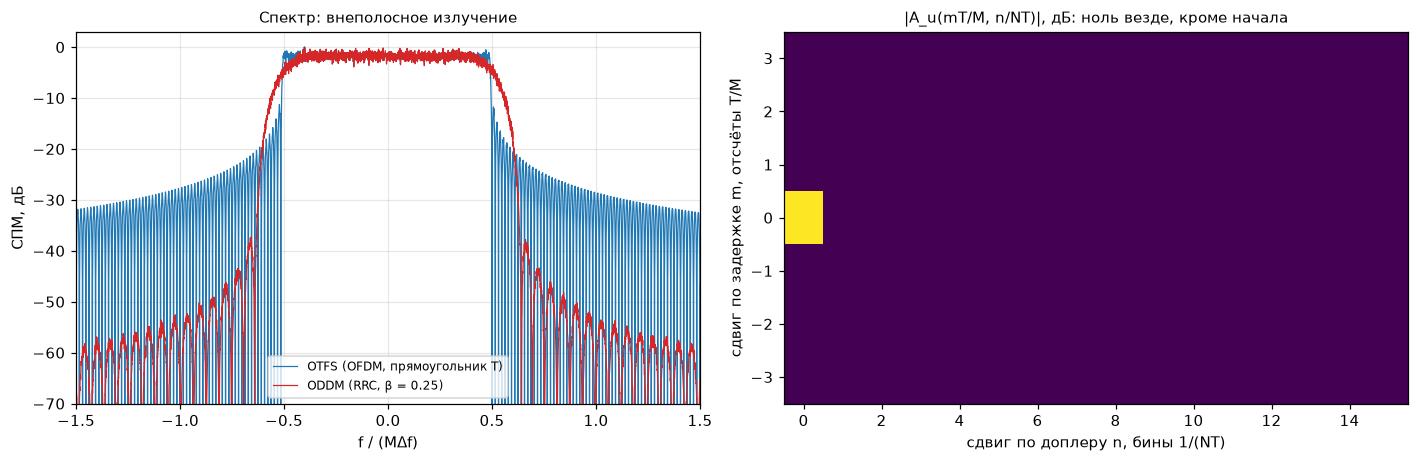

Наибольший боковой отсчёт функции неопределённости на решётке: -82 дБ (хвост RRC обрезан на ±8 отсчётов)


In [6]:
# ODDM: те же отсчёты, но каждый — RRC-импульс шириной T/M вместо прямоугольного окна T на «символ OFDM»
OS, SPAN = 8, 8
def rrc(beta, span=SPAN, os=OS):
    t = np.arange(-span * os, span * os + 1) / os
    with np.errstate(divide="ignore", invalid="ignore"):
        h = (np.sin(np.pi * t * (1 - beta)) + 4 * beta * t * np.cos(np.pi * t * (1 + beta))) / (np.pi * t * (1 - (4 * beta * t)**2))
    h[t == 0] = 1 - beta + 4 * beta / np.pi
    tb = np.isclose(np.abs(t), 1 / (4 * beta))
    h[tb] = beta / np.sqrt(2) * ((1 + 2 / np.pi) * np.sin(np.pi / (4 * beta)) + (1 - 2 / np.pi) * np.cos(np.pi / (4 * beta)))
    return h / np.sqrt(np.sum(h**2))
g = rrc(BETA)

def oddm_wave(x):
    s = frame(x, "otfs")                                       # отсчёты — как у OTFS
    up = np.zeros(s.shape[:-1] + (s.shape[-1] * OS,), complex); up[..., ::OS] = s
    return np.apply_along_axis(lambda v: np.convolve(v, g), -1, up)

def otfs_mc_wave(x):
    """OTFS как прекодер над OFDM: каждая поднесущая — прямоугольник длительности T (спектр sinc)"""
    X = x.reshape(x.shape[:-1] + (M, N))
    Xtf = np.fft.ifft(np.fft.fft(X, axis=-2), axis=-1)          # ISFFT
    G = np.zeros(x.shape[:-1] + (M * OS, N), complex)
    G[..., :M // 2, :] = Xtf[..., :M // 2, :]; G[..., -M // 2:, :] = Xtf[..., M // 2:, :]
    return (np.fft.ifft(G, axis=-2) * OS).swapaxes(-1, -2).reshape(x.shape[:-1] + (-1,))

B = 60; _, xb = qpsk_bits(B, rng)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for k, w, c in (("OTFS (OFDM, прямоугольник T)", otfs_mc_wave(xb), "C0"), (f"ODDM (RRC, β = {BETA})", oddm_wave(xb), "C3")):
    L = 2 ** int(np.ceil(np.log2(w.shape[-1])))
    P = np.mean(np.abs(np.fft.fft(w, L, axis=-1))**2, 0); P = np.fft.fftshift(P) / P.max()
    f = np.fft.fftshift(np.fft.fftfreq(L, 1 / (FS * OS)))
    ax[0].plot(f / (M * DF), 10 * np.log10(P + 1e-12), c, lw=0.8, label=k)
    oob = np.sum(P[np.abs(f) > 0.7 * M * DF]) / np.sum(P)
    print(f"{k:34}: доля мощности за пределами ±0.7·MΔf (край RRC — 0.625) {10*np.log10(oob):.1f} дБ")
ax[0].set_xlim(-1.5, 1.5); ax[0].set_ylim(-70, 3); ax[0].set_xlabel("f / (MΔf)"); ax[0].set_ylabel("СПМ, дБ"); ax[0].legend(fontsize=8)
ax[0].set_title("Спектр: внеполосное излучение", fontsize=10)
# ортогональность в DD: функция неопределённости RRC-импульса на решётке (mT/M, n/(NT))
pulse = np.zeros(N * M * OS, complex)
for n in range(N):
    pulse[n * M * OS: n * M * OS + len(g)] += g                # u(t) = Σ_n a(t − nT): N RRC-импульсов через T
tt = np.arange(len(pulse))
A = np.zeros((7, N))
for mi, m in enumerate(range(-3, 4)):
    sh = np.roll(pulse, m * OS)
    for n in range(N):
        A[mi, n] = np.abs(np.sum(pulse * np.conj(sh) * np.exp(-2j * np.pi * n * tt / (N * M * OS))))
A /= A[3, 0]
ax[1].imshow(20 * np.log10(A + 1e-9), origin="lower", aspect="auto", cmap="viridis", vmin=-60, vmax=0, extent=[-0.5, N - 0.5, -3.5, 3.5])
ax[1].set_xlabel("сдвиг по доплеру n, бины 1/(NT)"); ax[1].set_ylabel("сдвиг по задержке m, отсчёты T/M"); ax[1].grid(False)
ax[1].set_title("|A_u(mT/M, n/NT)|, дБ: ноль везде, кроме начала", fontsize=10)
plt.tight_layout(); plt.show()
A2 = A.copy(); A2[3, 0] = 0
print(f"Наибольший боковой отсчёт функции неопределённости на решётке: {20*np.log10(A2.max()):.0f} дБ (хвост RRC обрезан на ±{SPAN} отсчётов)")

## Итог серии: формы волны для каналов с доплером
| | OFDM | OTFS 1.0 | Zak-OTFS | AFDM | OCDM | OTSM | ODDM |
|---|---|---|---|---|---|---|---|
| Где символы | TF | DD | DD (решётка Зака) | DAFT, 1D | чирпы, 1D | задержка–секвентность | DD |
| Импульс | прямоугольник $T$ | прямоугольник $T$ | гаусс/sinc/RRC в DD | — | — | прямоугольник | RRC шириной $T/M$ |
| Модем | IFFT | ISFFT + IFFT | Зак | IFFT + 2 диагонали | IFFT + 1 диагональ | WHT (без умножений) | IDFT по доплеру + RRC |
| Разнесение по лучам | нет | да | да | да | частично | да | да |
| Дробный доплер | ICI | пол оценки | предсказуем | пол оценки | ICI | как OTFS | как OTFS |
| Спектр | sinc-хвосты | sinc-хвосты | от фильтра | sinc-хвосты | sinc-хвосты | от фильтра | компактный |
| Ноутбук | `lte_sim` | `otfs_sim` | `zak_sim` | `afdm_sim` | `ocdm_sim` | здесь | здесь |

Общий вывод серии: при линейном приёме форма волны — это унитарное преобразование одного и того же временного канала. Ёмкость у всех одна (раздел 2), а различаются три вещи:
1. **как символ распределён по лучам**, то есть какое разнесение без кода достаётся детектору: OFDM — никакого, OTFS/AFDM/OTSM — полное;
2. **насколько разрежен и предсказуем канал в «своей» области**, то есть сколько стоят оценка и детектор: OTFS — разрежен при целом доплере, Zak-OTFS — предсказуем при любом, AFDM — разрежен в 1D;
3. **сколько стоит модем и сколько он излучает мимо полосы**: OTSM — без умножений, ODDM — компактный спектр.

С хорошим кодом и перемежением OFDM (`lte_sim`) собирает большую часть того же разнесения, поэтому все эти схемы — кандидаты для сценариев с высоким доплером (поезда, самолёты, LEO-спутники, V2X), сенсинга (ISAC) и 6G, а не замена OFDM везде.

## Что покрутить
- `N = 64` — модулятор OTSM экономит ещё больше умножений ($\log_2N$ растёт); BER по-прежнему совпадает с OTFS
- `BETA = 0.05` — спектр ODDM почти прямоугольный, но импульс длиннее: при той же обрезке ±8 отсчётов боковые отсчёты функции неопределённости растут
- `BETA = 0.5` — внеполосное излучение ещё ниже, но полоса шире на 50 %
- `SPEED_KMH = 30` — доплер мал, и отклик OTSM в разделе 2 почти так же компактен, как у OTFS (WHT и DFT совпадают на постоянной функции, $k=0$)
- `P_PATHS = 2` — меньше разнесения у обеих схем, кривые раздела 3 положе, но по-прежнему вместе